In [11]:
import re
import pandas as pd
import matplotlib.pyplot as plt

DATA = "/Users/salmahirsi/Documents/GitHub/Politics-Network/data/"

# ───────────── 1. Indlæs mærkesagerne fra hjemmesiderne ─────────────
mk = pd.read_csv(DATA + "party_policies_2022/output/policy_pages.csv")
mk["usikker_dato"] = mk["capture_gap_status"] == "substantial_gap"     # arkivkopi langt fra valgdagen

# Hvordan partiet skriver sine mærkesager (set ved at læse dem)
SKRIVEFORM = {"NB": "Mange korte forslag", "RV": "Afsnit fra valgoplæg", "ALT": "Afsnit fra valgoplæg"}
mk["skriveform"] = mk["party_code"].map(SKRIVEFORM).fillna("Klare overskrifter")

# ───────────── 2. Ordlister for de 8 kategorier ─────────────
# "ord" = ord der starter med det · "*ord" = må stå inde i et ord · "=ord" = kun præcis det ord
KATEGORIER = {
    "Sundhed og ældrepleje": ["sundhed", "sygehus", "hospital", "sygeplejersk", "*læge", "*venteliste", "ventetid",
        "psykiatri", "patient", "behandling", "ældre", "plejehjem", "hjemmehjælp", "ældrepleje", "værdig"],
    "Klima og miljø": ["forurening","*klima", "grøn", "co2", "*energi", "vindmølle", "solcelle", "atomkraft", "fossil", "udledning",
        "omstilling", "landbrug", "miljø", "natur", "biodiversitet", "dyrevelfærd", "drikkevand", "*vand"],
    "Skoler og børnepasning": ["kultur","*skole", "uddannelse", "*gymnasi", "elever", "studerende", "=su", "daginstitution",
        "børnehave", "vuggestue", "pædagog", "normering", "minimumsnormering", "lærer", "universitet", "faglært"],
    "Økonomi og skat": ["økonomi", "*skat", "afgift", "inflation", "*pris", "vækst", "virksomhed", "erhverv",
        "iværksætter", "fradrag", "regning", "elafgift", "bureaukrati", "regler", "arbejdsmarked", "løn"],
    "Flygtninge og indvandrere": ["udlænding", "*asyl", "flygtning", "indvandr", "integration", "statsborgerskab",
        "hjemsend", "udvis", "familiesammenfør", "islam", "muslim", "grænse", "opholdstilladelse"],
    "Retspolitik og tryghed": ["kriminal", "straf", "politi", "vold", "bande", "fængsel", "domstol", "tryghed",
        "retssikkerhed", "retsstat", "retspolitik", "offer", "terror"],
    "Forsvar og sikkerhed": ["forsvar", "nato", "militær", "soldat", "værnepligt", "sikkerhedspolitik", "ukraine",
        "rusland", "=krig", "beredskab"],
    "Pension og tilbagetrækning": ["pension", "efterløn", "=arne", "seniorpension", "tilbagetrækning", "pensionist"],
}

def rammer(ord_, stamme):
    if stamme.startswith("="):
        return ord_ == stamme[1:]
    if stamme.startswith("*"):
        return stamme[1:] in ord_
    return ord_.startswith(stamme)

def tael(tekst):
    """Hvor mange ord i teksten rammer hver kategori?"""
    ord_ = re.findall(r"[a-zæøåé0-9]+", str(tekst).lower())
    return {kat: sum(any(rammer(o, s) for s in stammer) for o in ord_) for kat, stammer in KATEGORIER.items()}

# ───────────── 3. Klassificér: overskriften først, brødteksten som reserve ─────────────
titel = pd.DataFrame([tael(t) for t in mk["title"]])
tekst = pd.DataFrame([tael(t) for t in mk["text"]])

def vaelg(i):
    if titel.loc[i].max() > 0:                                  # overskriften nævner en kategori
        kandidater = titel.loc[i][titel.loc[i] == titel.loc[i].max()].index
        return tekst.loc[i, kandidater].idxmax(), "overskrift"  # ved uafgjort i overskriften afgør teksten
    if tekst.loc[i].max() > 0:
        return tekst.loc[i].idxmax(), "brødtekst"
    return "Andet", "ingen"

mk[["kategori", "afgjort_af"]] = [vaelg(i) for i in mk.index]
mk["entydig"] = (tekst.max(axis=1) / tekst.sum(axis=1).replace(0, 1)).round(2)
mk["tjek"] = (mk["afgjort_af"] != "overskrift") & (mk["entydig"] < 0.5)

# Rettelser efter at have læst de tvivlsomme i hånden
RETTELSER = {
    "Stærkere ånd, rigere kultur": "Andet",
    # "Overskrift": "Rigtig kategori",
}
mk.loc[mk["title"].isin(RETTELSER), "kategori"] = mk["title"].map(RETTELSER)

# ───────────── 4. Overblik ─────────────
print(f"{len(mk)} mærkesager fra {mk['party_code'].nunique()} partier\n")
print("Hvordan blev kategorien fundet, pr. skriveform:")
print(pd.crosstab(mk["skriveform"], mk["afgjort_af"], margins=True).to_string())
print(f"\nBør tjekkes i hånden: {mk['tjek'].sum()}")
print("\nAntal mærkesager pr. kategori:")
print(mk["kategori"].value_counts().to_string())

mk[["party", "party_code", "skriveform", "title", "kategori", "afgjort_af", "entydig", "tjek",
    "usikker_dato", "text"]].to_csv(DATA + "maerkesager_klassificeret.csv", index=False, encoding="utf-8-sig")

184 mærkesager fra 12 partier

Hvordan blev kategorien fundet, pr. skriveform:
afgjort_af            brødtekst  overskrift  All
skriveform                                      
Afsnit fra valgoplæg         12           8   20
Klare overskrifter           20          44   64
Mange korte forslag          49          51  100
All                          81         103  184

Bør tjekkes i hånden: 15

Antal mærkesager pr. kategori:
kategori
Økonomi og skat               53
Sundhed og ældrepleje         30
Klima og miljø                29
Skoler og børnepasning        24
Flygtninge og indvandrere     19
Retspolitik og tryghed        19
Forsvar og sikkerhed           7
Pension og tilbagetrækning     2
Andet                          1


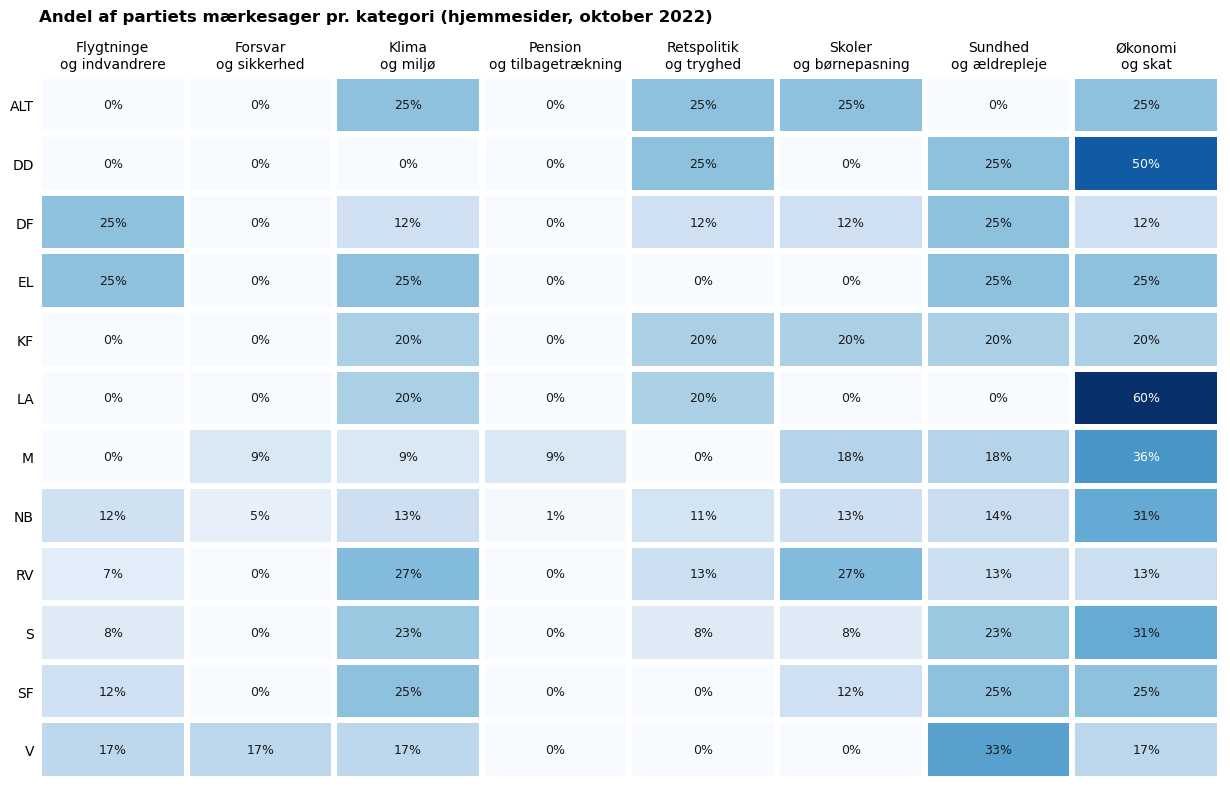

In [12]:
# ───────────── Heatmap: andel af partiets mærkesager pr. kategori ─────────────
mk_plot = mk[mk["kategori"] != "Andet"]                         # fjern "Andet"
andel = pd.crosstab(mk_plot["party_code"], mk_plot["kategori"], normalize="index")
vmax = max(0.4, andel.values.max())

fig, ax = plt.subplots(figsize=(1.3 * andel.shape[1] + 2, 0.5 * andel.shape[0] + 2))
# pcolormesh med hvide kanter giver mellemrum mellem felterne
felter = ax.pcolormesh(andel.values, cmap="Blues", vmin=0, vmax=vmax, edgecolors="white", linewidth=3)
ax.invert_yaxis()                                                # første parti øverst
ax.set_xticks([j + 0.5 for j in range(andel.shape[1])], [k.replace(" og ", "\nog ") for k in andel.columns])
ax.set_yticks([i + 0.5 for i in range(andel.shape[0])], andel.index)   # kun partiet
ax.xaxis.tick_top(); ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(andel.shape[0]):
    for j in range(andel.shape[1]):
        v = andel.values[i, j]
        ax.text(j + 0.5, i + 0.5, f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.6 * vmax else "#1a1a1a")
ax.set_title("Andel af partiets mærkesager pr. kategori (hjemmesider, oktober 2022)",
             loc="left", fontsize=12, fontweight="bold", pad=14)
fig.tight_layout(); fig.savefig(DATA + "fig_maerkesager_pr_parti.png", dpi=160); plt.show()